In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_ROOMS = 4     # number of rooms
STEPS = 50      # steps in one run
RUNS = 100      # number of experiments per agent

In [6]:
def simulate(agent, seed):
    rng = np.random.default_rng(seed)
    dirt = rng.random(N_ROOMS) < 0.5               # True = dirty room
    known_clean = np.zeros(N_ROOMS, dtype=bool)    # memory of the "model" agent
    pos, direction, score = 0, 1, 0

    for step in range(STEPS):
        known_clean[pos] = not dirt[pos]

        # 1) choose an action
        if agent == "random":
            action = rng.choice(["Left", "Right", "Suck"])
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Left", "Right"])
        elif known_clean.all():
            action = "NoOp"
        else:
            if pos == N_ROOMS - 1:
                direction = -1
            if pos == 0:
                direction = 1
            action = "Right" if direction == 1 else "Left"

        # 2) apply the action
        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        score += (~dirt).sum()                     # +1 for each clean room
    return int(score)

In [7]:
for agent in ["random", "reflex", "model"]:
    print(agent, simulate(agent, seed=1))

random 184
reflex 190
model 198


In [8]:

rows = []
for agent in ["random", "reflex", "model"]:
    for seed in range(RUNS):
        rows.append({"agent": agent, "score": simulate(agent, seed)})

df = pd.DataFrame(rows)
print(df.head())
summary = df.groupby("agent")["score"].agg(["mean", "std"]).round(1)
print(summary)

    agent  score
0  random    178
1  random    184
2  random    142
3  random    157
4  random    195
         mean   std
agent              
model   195.7   2.9
random  167.2  24.9
reflex  188.5  10.9


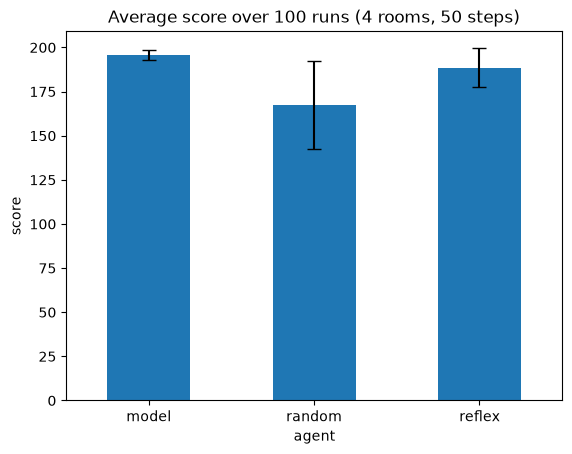

In [9]:
summary["mean"].plot(kind="bar", yerr=summary["std"], capsize=5)
plt.title("Average score over 100 runs (4 rooms, 50 steps)")
plt.ylabel("score")
plt.xticks(rotation=0)
plt.show()